# DSCI 552 — Homework 5
Matthew Hall

## 1. Decision Trees as Interpretable Models
### (a) Load and inspect the Acute Inflammations dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import StratifiedKFold, GridSearchCV

RANDOM_STATE = 42

In [2]:
columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "urethral_burning",
    "bladder_inflammation",
    "nephritis"
]

diagnosis = pd.read_csv(
    "/content/diagnosis.data",
    sep="\t",
    header=None,
    names=columns,
    encoding="utf-16",
    decimal=","
)

# Encode no as 0 and yes as 1.
for column in columns[1:]:
    diagnosis[column] = diagnosis[column].map({"no": 0, "yes": 1})

print("Dataset shape:", diagnosis.shape)
print("Missing values:", diagnosis.isna().sum().sum())
display(diagnosis.head())

Dataset shape: (120, 8)
Missing values: 0


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,urethral_burning,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build and plot a decision tree

I used the label powerset approach, treating each combination of the two diagnoses as a separate class. This lets a single decision tree predict whether a patient has neither condition, bladder inflammation only, nephritis only, or both conditions. As instructed, the tree is trained on the whole dataset.

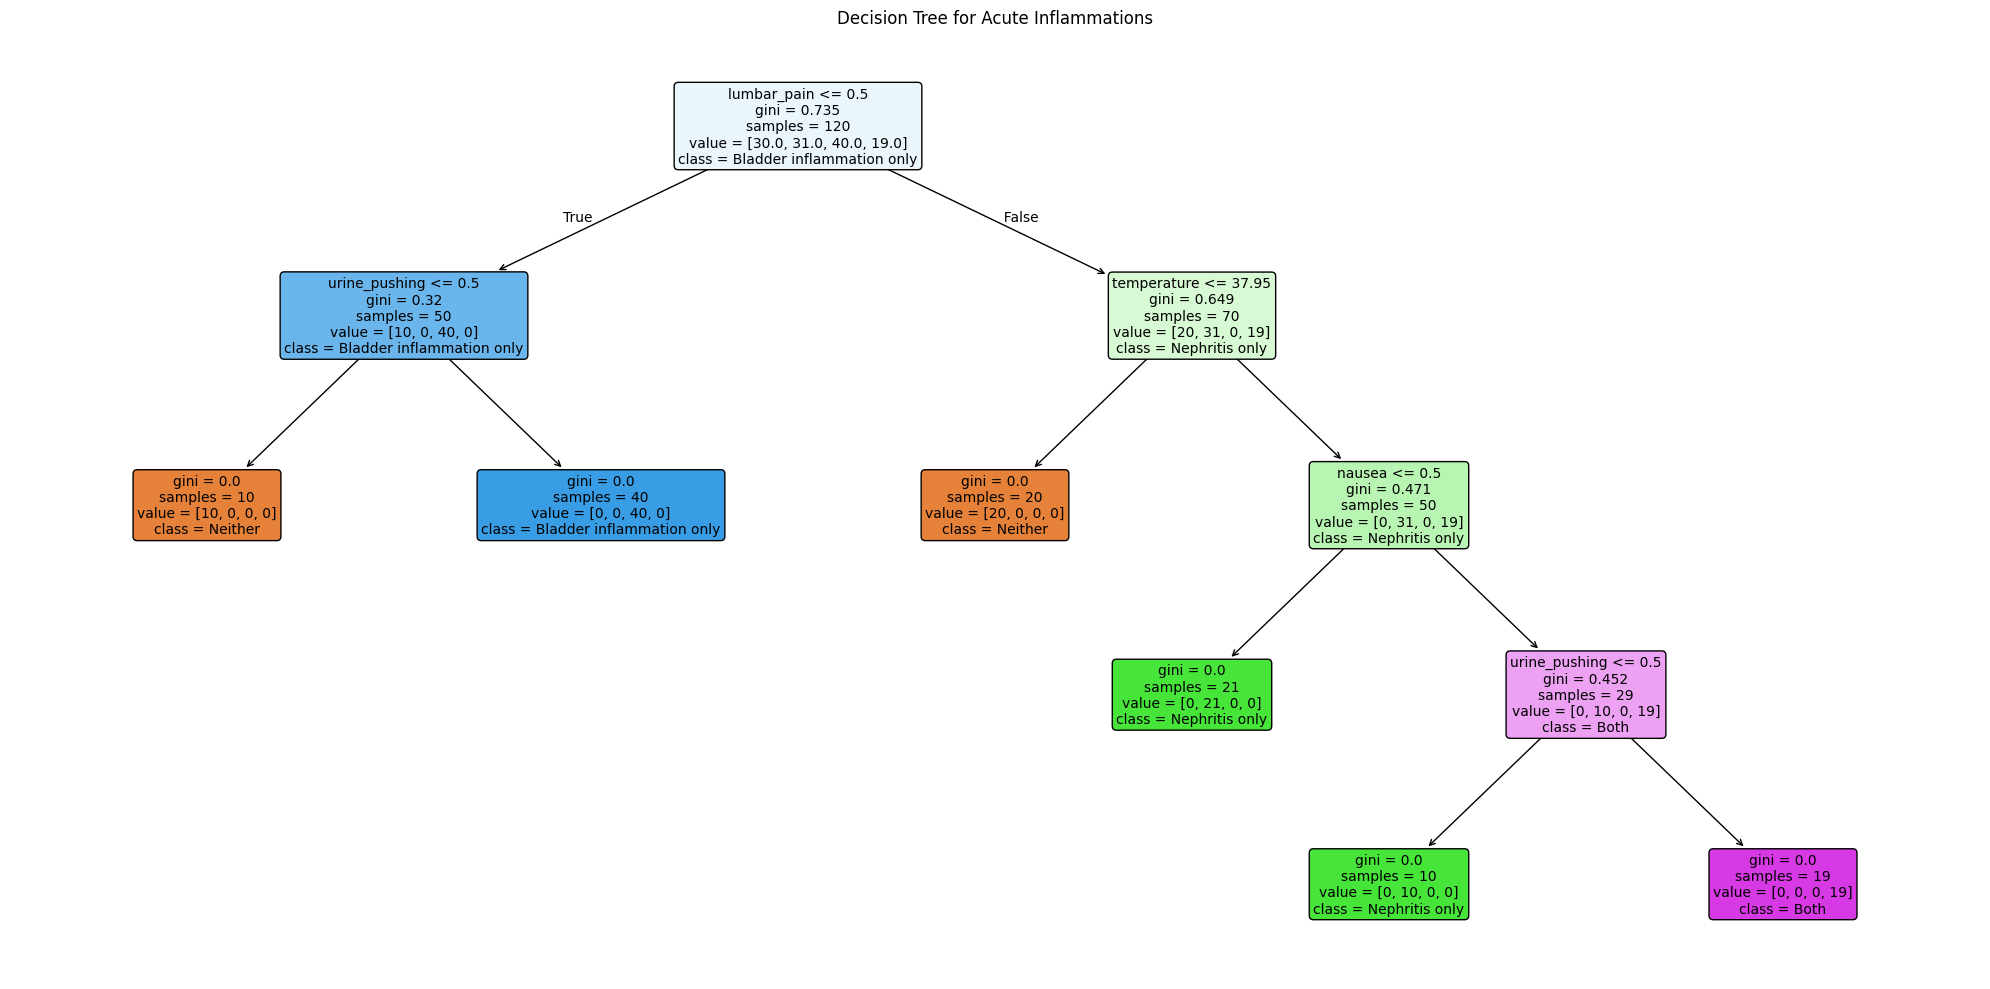

Tree depth: 4
Number of leaves: 6
Training accuracy: 100.00%


In [3]:
X_diagnosis = diagnosis.iloc[:, :6].copy()

# Encode the two diagnoses as four possible classes.
# 0 = neither, 1 = nephritis only,
# 2 = bladder inflammation only, 3 = both.
y_diagnosis = (
    2 * diagnosis["bladder_inflammation"]
    + diagnosis["nephritis"]
)

diagnosis_labels = {
    0: "Neither",
    1: "Nephritis only",
    2: "Bladder inflammation only",
    3: "Both"
}

tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree.fit(X_diagnosis, y_diagnosis)

plt.figure(figsize=(20, 10))
plot_tree(
    tree,
    feature_names=X_diagnosis.columns.tolist(),
    class_names=[diagnosis_labels[int(c)] for c in tree.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree for Acute Inflammations")
plt.tight_layout()
plt.show()

print("Tree depth:", tree.get_depth())
print("Number of leaves:", tree.get_n_leaves())
print(f"Training accuracy: {tree.score(X_diagnosis, y_diagnosis):.2%}")

### (c) Convert the tree into IF–THEN rules

Each path from the root to a leaf gives one IF–THEN rule. For binary symptoms, a value of 0 means the symptom is absent and 1 means it is present. The full tree has six leaves, giving six rules.

In [4]:
def get_if_then_rules(model, feature_names, class_labels):
    structure = model.tree_
    rules = []

    def walk(node, conditions):
        left = structure.children_left[node]
        right = structure.children_right[node]

        # A leaf predicts the class with the largest count.
        if left == right:
            class_index = int(np.argmax(structure.value[node][0]))
            predicted_class = int(model.classes_[class_index])
            outcome = class_labels[predicted_class]
            condition_text = " AND ".join(conditions) or "TRUE"
            samples = structure.n_node_samples[node]

            rules.append(
                f"IF {condition_text} THEN {outcome} "
                f"(samples = {samples})."
            )
            return

        feature = feature_names[structure.feature[node]]
        threshold = structure.threshold[node]

        if feature == "temperature":
            left_condition = f"{feature} <= {threshold:.2f}"
            right_condition = f"{feature} > {threshold:.2f}"
        else:
            left_condition = f"{feature} = no"
            right_condition = f"{feature} = yes"

        walk(left, conditions + [left_condition])
        walk(right, conditions + [right_condition])

    walk(0, [])
    return rules


full_tree_rules = get_if_then_rules(
    tree,
    X_diagnosis.columns.tolist(),
    diagnosis_labels
)

for number, rule in enumerate(full_tree_rules, start=1):
    print(f"Rule {number}: {rule}\n")

Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN Neither (samples = 10).

Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN Bladder inflammation only (samples = 40).

Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN Neither (samples = 20).

Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = no THEN Nephritis only (samples = 21).

Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = no THEN Nephritis only (samples = 10).

Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = yes THEN Both (samples = 19).



### (d) Cost-complexity pruning

I compared cost-complexity pruning parameters using five-fold stratified cross-validation. I use the one-standard-error rule to select a simpler tree whose mean validation accuracy is within one standard error of the best mean accuracy. I then fit the selected tree on the full dataset and display its plot and IF–THEN rules.

,alpha,mean_cv_accuracy,standard_error,leaves,depth
0,0.000000,0.991667,0.008333,6,4
1,0.098167,0.858333,0.025000,4,2
2,0.133333,0.758333,0.033333,3,2
3,0.182000,0.666667,0.029463,2,1
4,0.222917,0.483333,0.061237,1,0


Selected alpha: 0.000000
Selected mean CV accuracy: 99.17%
Pruned tree depth: 4
Pruned tree leaves: 6
Training accuracy: 100.00%


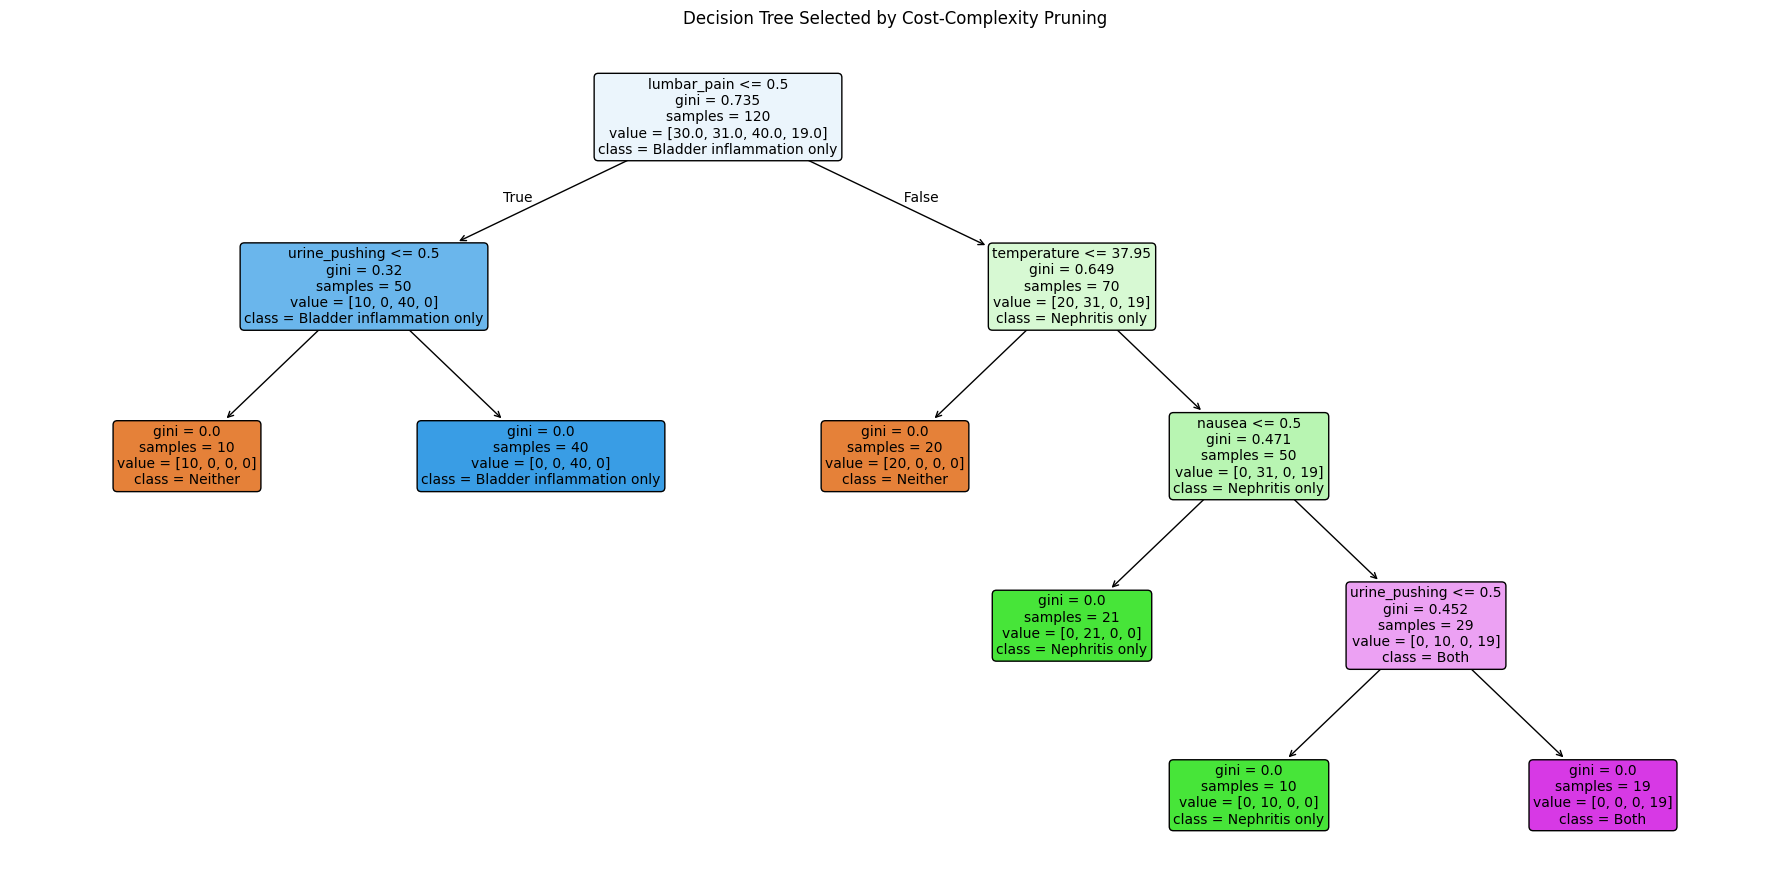

Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN Neither (samples = 10).

Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN Bladder inflammation only (samples = 40).

Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN Neither (samples = 20).

Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = no THEN Nephritis only (samples = 21).

Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = no THEN Nephritis only (samples = 10).

Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = yes THEN Both (samples = 19).



In [5]:
from sklearn.model_selection import cross_val_score

# Obtain candidate pruning parameters.
pruning_path = tree.cost_complexity_pruning_path(
    X_diagnosis, y_diagnosis
)
alphas = np.unique(pruning_path.ccp_alphas)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

results = []

for alpha in alphas:
    candidate = DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        ccp_alpha=float(alpha)
    )

    scores = cross_val_score(
        candidate,
        X_diagnosis,
        y_diagnosis,
        cv=cv,
        scoring="accuracy"
    )

    candidate.fit(X_diagnosis, y_diagnosis)

    results.append({
        "alpha": alpha,
        "mean_cv_accuracy": scores.mean(),
        "standard_error": scores.std(ddof=1) / np.sqrt(len(scores)),
        "leaves": candidate.get_n_leaves(),
        "depth": candidate.get_depth()
    })

pruning_results = pd.DataFrame(results)

# Apply the one-standard-error rule.
best_index = pruning_results["mean_cv_accuracy"].idxmax()
cutoff = (
    pruning_results.loc[best_index, "mean_cv_accuracy"]
    - pruning_results.loc[best_index, "standard_error"]
)

eligible = pruning_results[
    pruning_results["mean_cv_accuracy"] >= cutoff
]

selected = eligible.sort_values(
    ["leaves", "alpha"],
    ascending=[True, False]
).iloc[0]

pruned_tree = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
    ccp_alpha=float(selected["alpha"])
)
pruned_tree.fit(X_diagnosis, y_diagnosis)

display(pruning_results)

print(f"Selected alpha: {selected['alpha']:.6f}")
print(f"Selected mean CV accuracy: {selected['mean_cv_accuracy']:.2%}")
print("Pruned tree depth:", pruned_tree.get_depth())
print("Pruned tree leaves:", pruned_tree.get_n_leaves())
print(
    f"Training accuracy: "
    f"{pruned_tree.score(X_diagnosis, y_diagnosis):.2%}"
)

plt.figure(figsize=(18, 9))
plot_tree(
    pruned_tree,
    feature_names=X_diagnosis.columns.tolist(),
    class_names=[
        diagnosis_labels[int(c)] for c in pruned_tree.classes_
    ],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Selected by Cost-Complexity Pruning")
plt.tight_layout()
plt.show()

pruned_rules = get_if_then_rules(
    pruned_tree,
    X_diagnosis.columns.tolist(),
    diagnosis_labels
)

for number, rule in enumerate(pruned_rules, start=1):
    print(f"Rule {number}: {rule}\n")

The one-standard-error rule selected alpha = 0, retaining the original tree with six leaves and depth four. Its mean cross-validation accuracy was 99.17%, with a standard error of 0.83 percentage points. The next smaller candidate had four leaves, but its mean validation accuracy dropped to 85.83%, below the 98.33% cutoff. Therefore, the pruning procedure did not justify simplifying the tree further under this criterion. The selected tree still provides a relatively interpretable model with six IF–THEN rules using only four of the six predictors.

## 2. The LASSO and Boosting for Regression
### (a) Load the data and create the training and test sets
### (b) Remove nonpredictive attributes and impute missing values

The response is ViolentCrimesPerPop. I remove the five nonpredictive attributes: state, county, community, communityname, and fold. I use the first 1,495 observations for training and the remaining observations for testing, preserving the original order. Missing predictor values are replaced with training-set medians, which prevents information from the test set from influencing preprocessing.

In [6]:
from sklearn.impute import SimpleImputer

# Read the column names from the accompanying description file.
with open("/content/communities.names", encoding="utf-8") as file:
    feature_names = [
        line.split()[1]
        for line in file
        if line.lower().startswith("@attribute")
    ]

communities = pd.read_csv(
    "/content/communities.data",
    header=None,
    names=feature_names,
    na_values="?"
)

nonpredictive = [
    "state", "county", "community", "communityname", "fold"
]
target = "ViolentCrimesPerPop"

X_crime = communities.drop(columns=nonpredictive + [target])
y_crime = communities[target]

# Preserve the specified row order.
X_train_raw = X_crime.iloc[:1495].copy()
X_test_raw = X_crime.iloc[1495:].copy()

y_train = y_crime.iloc[:1495].copy()
y_test = y_crime.iloc[1495:].copy()

# Learn medians from training data only.
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=X_train_raw.columns,
    index=X_train_raw.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_test_raw.columns,
    index=X_test_raw.index
)

print("Original dataset shape:", communities.shape)
print("Training predictors:", X_train.shape)
print("Test predictors:", X_test.shape)
print("Missing training predictor values before imputation:",
      X_train_raw.isna().sum().sum())
print("Missing test predictor values before imputation:",
      X_test_raw.isna().sum().sum())
print("Missing predictor values after imputation:",
      X_train.isna().sum().sum() + X_test.isna().sum().sum())
print("Missing response values:", y_crime.isna().sum())

display(X_train.head())

Original dataset shape: (1994, 128)
Training predictors: (1495, 122)
Test predictors: (499, 122)
Missing training predictor values before imputation: 27633
Missing test predictor values before imputation: 9218
Missing predictor values after imputation: 0
Missing response values: 0


,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop
0,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.29,0.12,0.26,0.20,0.06,0.04,0.90,0.5,0.32,0.14
1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,0.28,0.02,0.12,0.45,0.07,0.03,0.76,0.5,0.00,0.15
2,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,0.28,0.01,0.21,0.02,0.07,0.03,0.76,0.5,0.00,0.15
3,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,...,0.28,0.02,0.39,0.28,0.07,0.03,0.76,0.5,0.00,0.15
4,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,...,0.28,0.04,0.09,0.02,0.07,0.03,0.76,0.5,0.00,0.15


### (c) Correlation matrix

I calculate Pearson correlations using the imputed training data, including the response, ViolentCrimesPerPop. Positive correlations indicate that two variables tend to increase together, while negative correlations indicate that one tends to decrease as the other increases. Correlation describes association and does not establish causation.

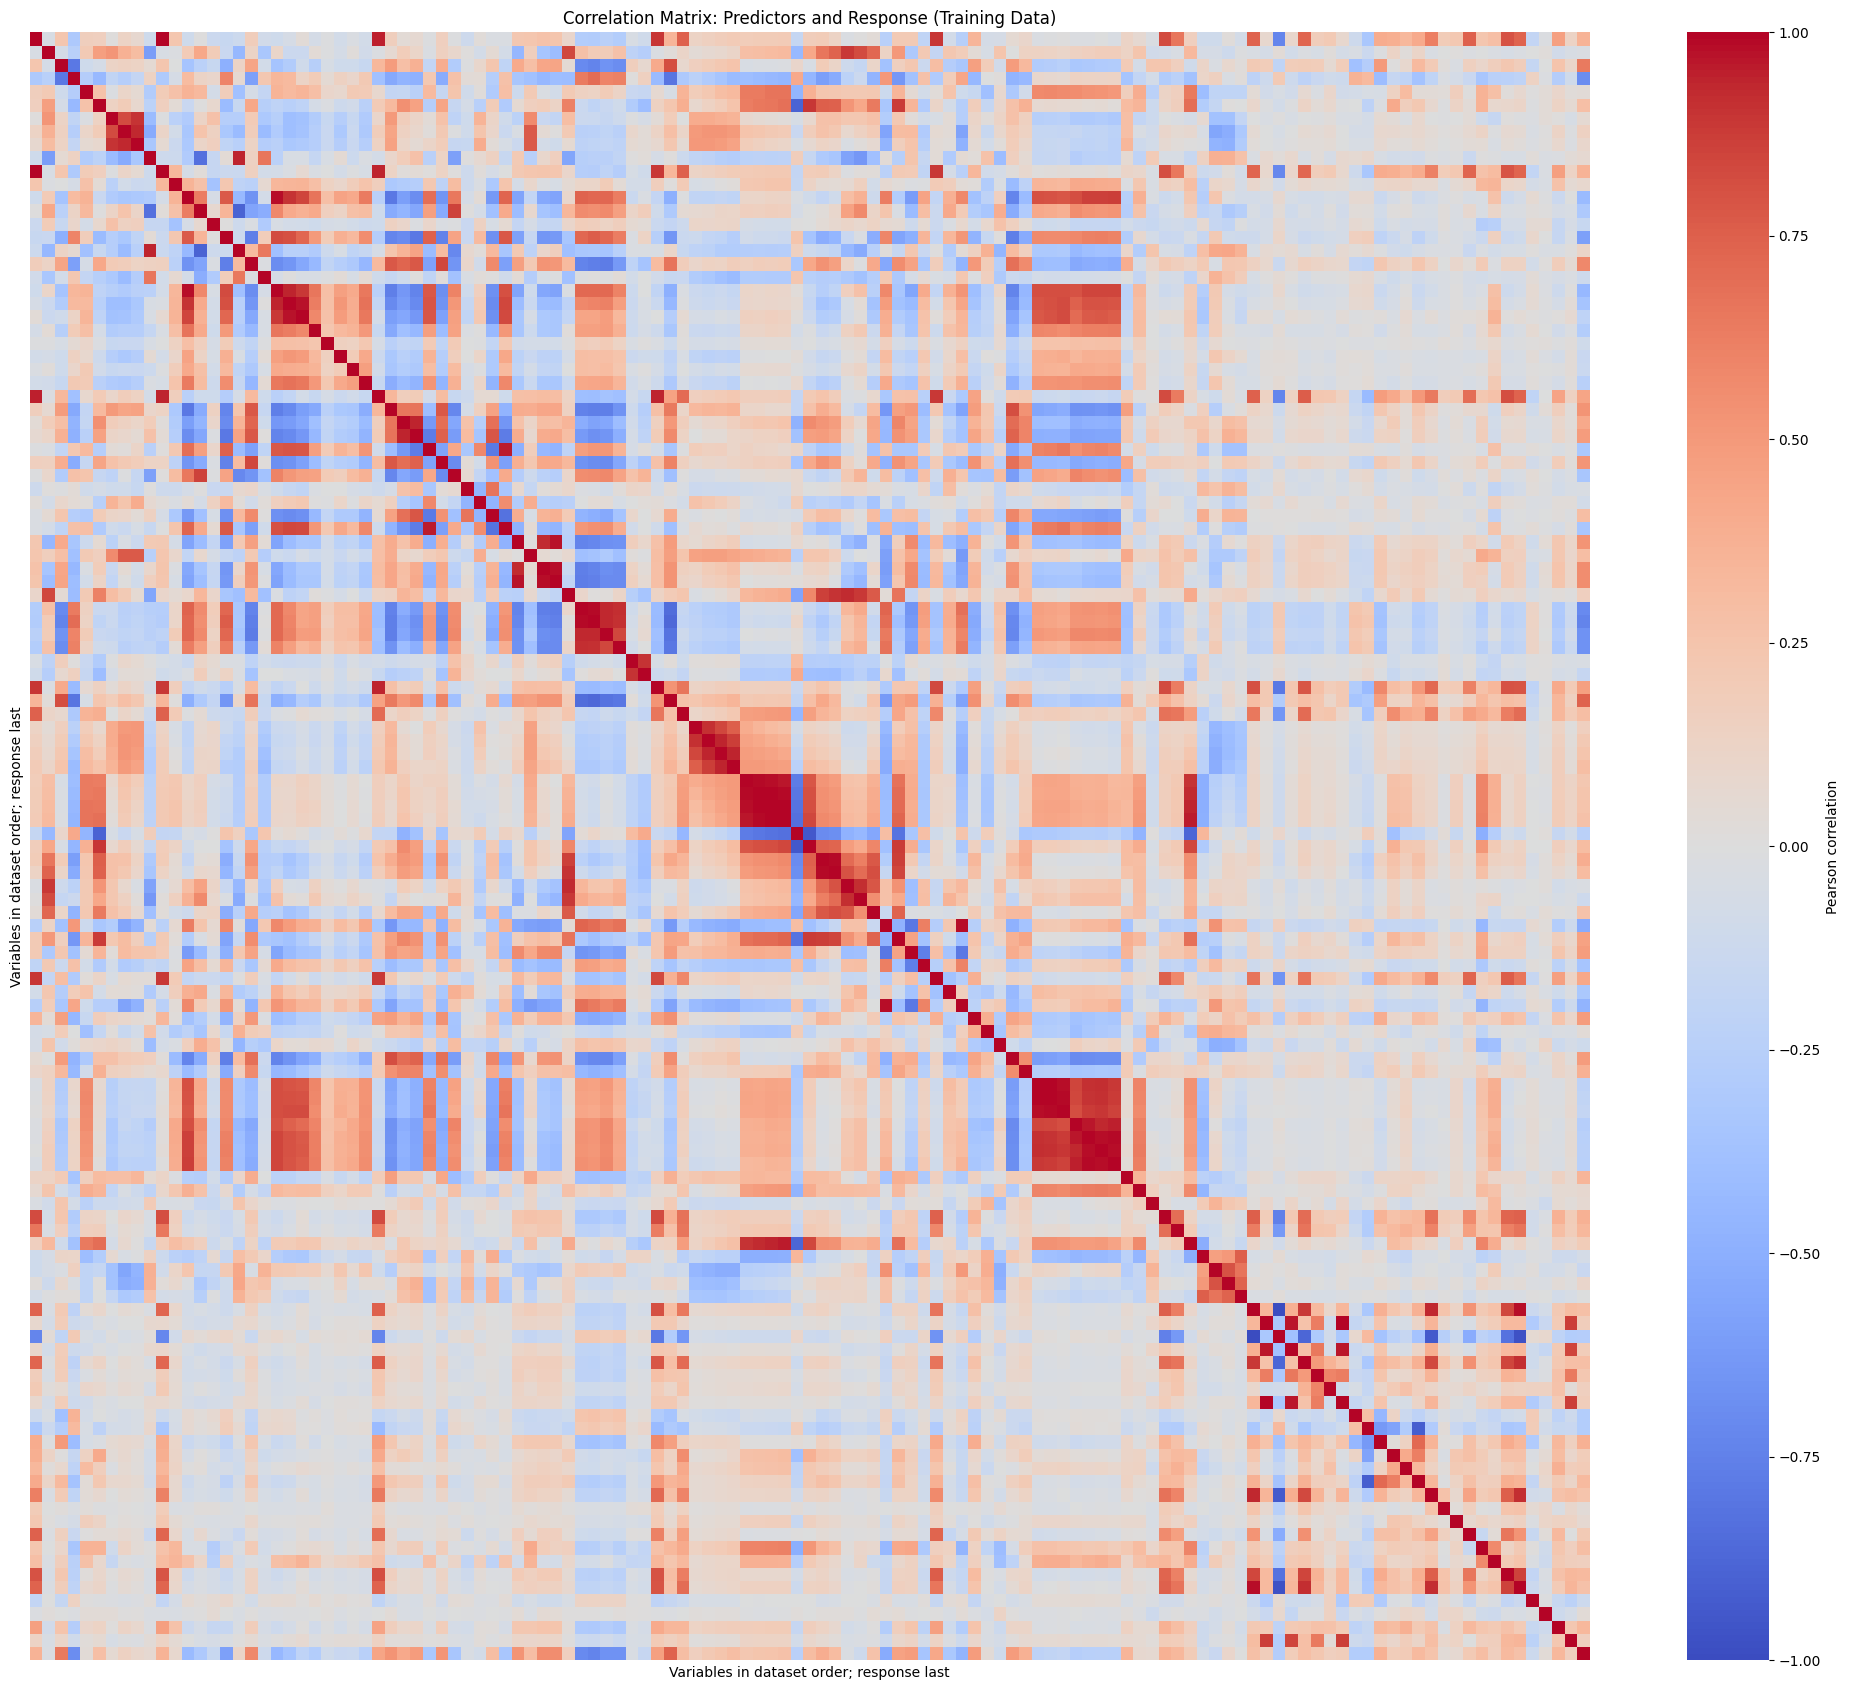

,Correlation with ViolentCrimesPerPop
PctIlleg,0.741866
PctKids2Par,-0.741233
PctFam2Par,-0.710619
racePctWhite,-0.690614
PctTeen2Par,-0.668713
PctYoungKids2Par,-0.666485
racepctblack,0.644094
pctWInvInc,-0.586759
pctWPubAsst,0.581713
FemalePctDiv,0.561824


In [7]:
# Include the response alongside the 122 predictors.
crime_train = X_train.copy()
crime_train[target] = y_train

correlation_matrix = crime_train.corr()

plt.figure(figsize=(20, 17))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={"label": "Pearson correlation"}
)
plt.title("Correlation Matrix: Predictors and Response (Training Data)")
plt.xlabel("Variables in dataset order; response last")
plt.ylabel("Variables in dataset order; response last")
plt.tight_layout()
plt.show()

# Show the strongest predictor-response associations separately.
target_correlations = (
    correlation_matrix[target]
    .drop(target)
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

display(
    target_correlations.head(10)
    .rename("Correlation with ViolentCrimesPerPop")
    .to_frame()
)

PctIlleg has the strongest positive correlation with violent crime (0.742), while PctKids2Par has the strongest negative correlation (-0.741). Several other family-structure and demographic variables also have relatively strong associations with the response. These are observational, community-level correlations, so they do not establish causation. The predictor-response correlations alone also do not tell us which variables will remain useful after accounting for other predictors.

### (d) Coefficient of variation

I calculate each predictor’s coefficient of variation as its sample standard deviation divided by its mean, using the imputed training data.

In [8]:
feature_means = X_train.mean()
feature_stds = X_train.std(ddof=1)

cv_table = pd.DataFrame({
    "Mean": feature_means,
    "Sample standard deviation": feature_stds,
    "CV": feature_stds / feature_means.replace(0, np.nan)
}).sort_values("CV", ascending=False)

cv_table.index.name = "Feature"

# Display all 122 predictors.
with pd.option_context("display.max_rows", None):
    display(cv_table)

print("Number of predictors:", len(cv_table))
print("Predictors with undefined CV:", cv_table["CV"].isna().sum())

,Mean,Sample standard deviation,CV
Feature,,,
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105


Number of predictors: 122
Predictors with undefined CV: 0


### (e) Explore the 11 predictors with the highest CV

I select the 11 predictors with the largest coefficients of variation. For each predictor, I plot its relationship with ViolentCrimesPerPop and use a box plot to examine its distribution.

Selected predictors:
PctPolicAsian
NumStreet
NumInShelters
NumIlleg
NumImmig
LemasPctOfficDrugUn
NumUnderPov
LemasSwornFT
population
numbUrban
HousVacant


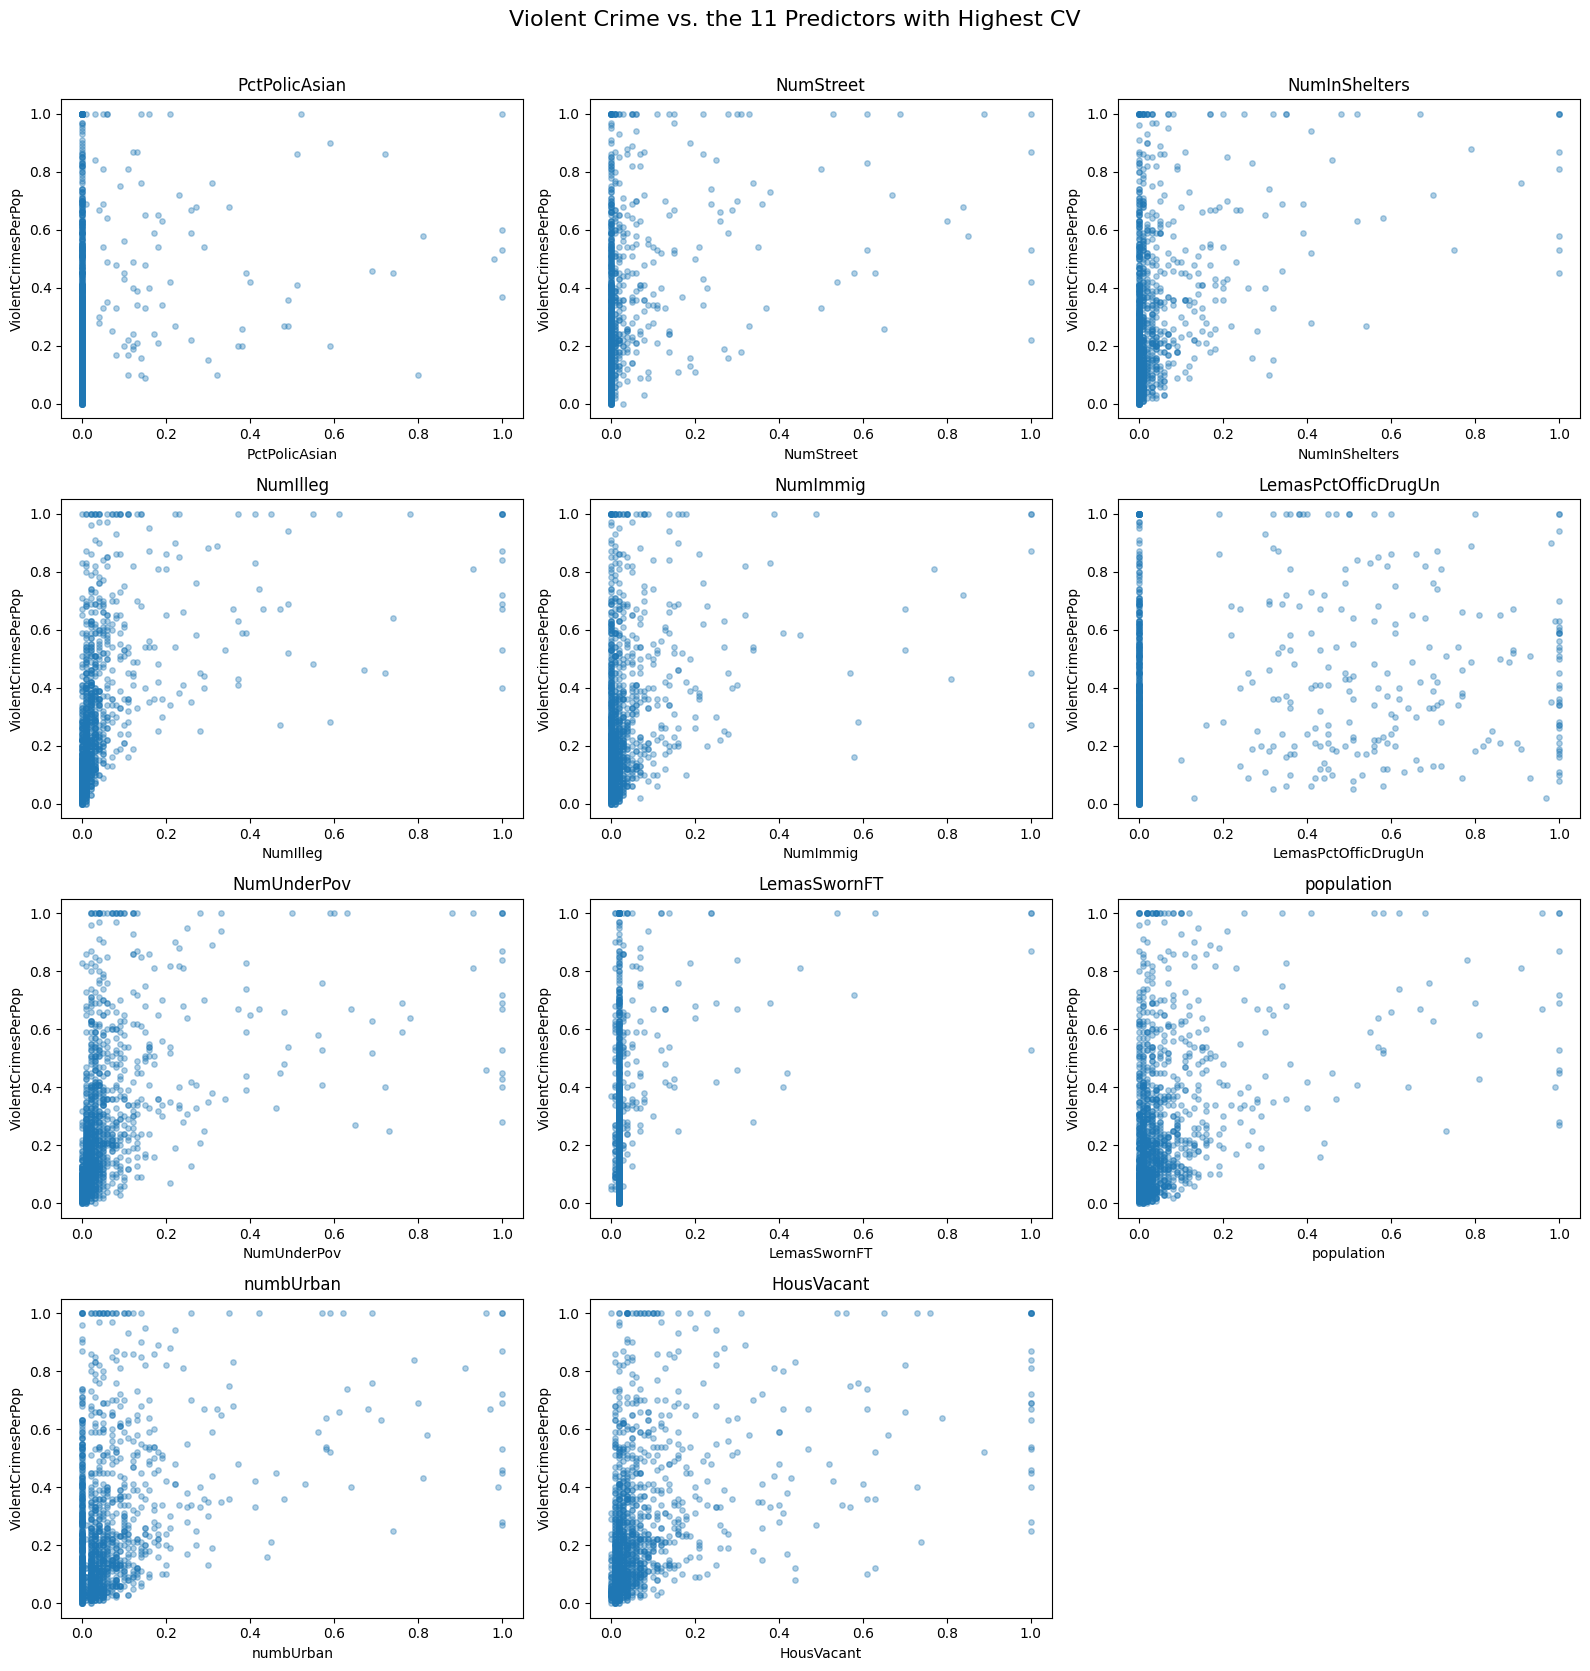

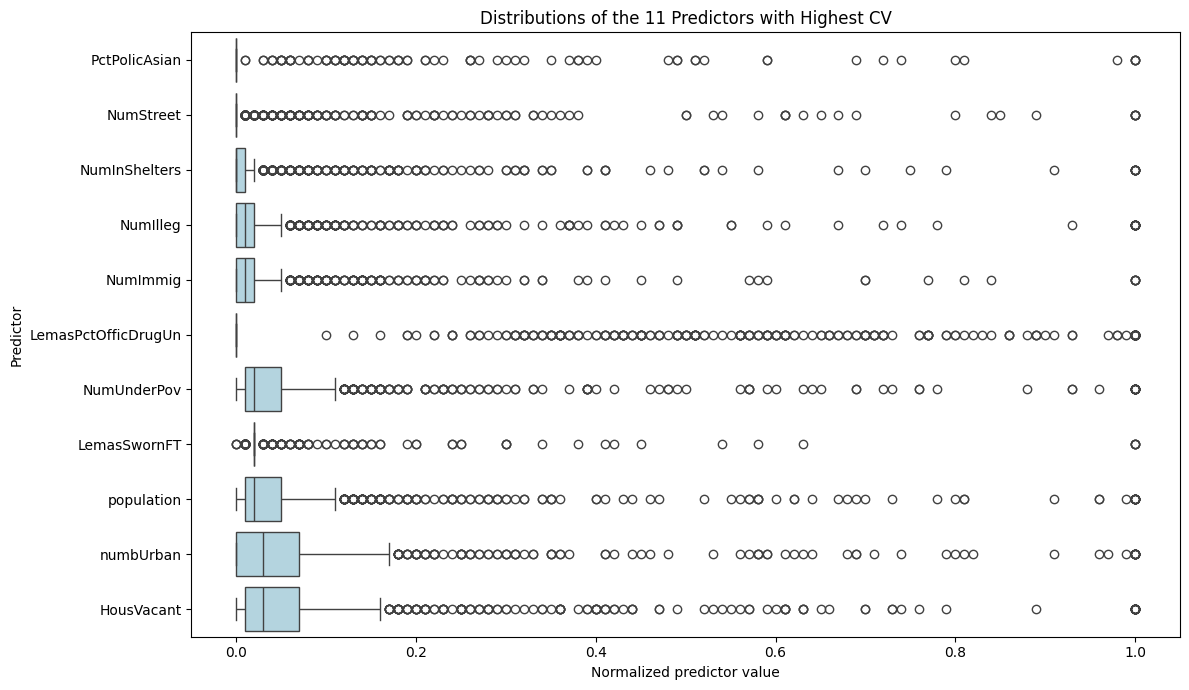

In [9]:
n_selected = int(np.sqrt(128))
top_cv_features = cv_table.head(n_selected).index.tolist()

print("Selected predictors:")
for feature in top_cv_features:
    print(feature)

# Scatter plots: each predictor versus the response.
fig, axes = plt.subplots(4, 3, figsize=(16, 17))

for ax, feature in zip(axes.flat, top_cv_features):
    ax.scatter(
        X_train[feature],
        y_train,
        alpha=0.35,
        s=15
    )
    ax.set_xlabel(feature)
    ax.set_ylabel(target)
    ax.set_title(feature)

for ax in axes.flat[len(top_cv_features):]:
    ax.set_visible(False)

fig.suptitle(
    "Violent Crime vs. the 11 Predictors with Highest CV",
    fontsize=16
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# Box plots: distribution of each selected predictor.
plt.figure(figsize=(12, 7))
sns.boxplot(
    data=X_train[top_cv_features],
    orient="h",
    color="lightblue"
)
plt.title("Distributions of the 11 Predictors with Highest CV")
plt.xlabel("Normalized predictor value")
plt.ylabel("Predictor")
plt.tight_layout()
plt.show()

Many of the selected predictors are concentrated near zero, with relatively few observations at larger values. Features such as NumIlleg, NumUnderPov, and HousVacant suggest positive associations with violent crime, although the response varies substantially at similar predictor values. High CV does not necessarily imply strong predictive ability. Scatter plots alone cannot establish statistical significance because they do not quantify uncertainty or account for relationships among predictors. Formal inference would require an appropriate statistical model and its assumptions.

### (f) Least-squares linear regression

I fit an ordinary least-squares regression using all 122 predictors and the training-set median imputations. I evaluate predictions on the 499 test observations, using mean squared error (MSE) as the primary test error. I also report RMSE and R² for context.

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

ols = LinearRegression()
ols.fit(X_train, y_train)

ols_predictions = ols.predict(X_test)

ols_mse = mean_squared_error(y_test, ols_predictions)
ols_rmse = np.sqrt(ols_mse)
ols_r2 = r2_score(y_test, ols_predictions)

# Keep results together for comparison with later models.
model_results = [{
    "Model": "Least squares",
    "Test MSE": ols_mse,
    "Test RMSE": ols_rmse,
    "Test R²": ols_r2
}]

display(pd.DataFrame(model_results).set_index("Model"))

,Test MSE,Test RMSE,Test R²
Model,,,
Least squares,0.017966,0.134038,0.622204


### (g) Ridge regression

I select the ridge penalty using five-fold cross-validation, minimizing mean squared error. Median imputation and standardization are fitted separately within each training fold to avoid validation leakage. After selecting the penalty, I refit the pipeline on the full training set and evaluate it on the test set.

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold

regression_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"ridge__alpha": np.logspace(-4, 5, 100)},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=-1
)

ridge_search.fit(X_train_raw, y_train)
ridge_predictions = ridge_search.predict(X_test_raw)

ridge_mse = mean_squared_error(y_test, ridge_predictions)

ridge_result = {
    "Model": "Ridge",
    "Test MSE": ridge_mse,
    "Test RMSE": np.sqrt(ridge_mse),
    "Test R²": r2_score(y_test, ridge_predictions)
}

# Replace any prior Ridge entry if this cell is rerun.
model_results = [
    result for result in model_results
    if result["Model"] != "Ridge"
]
model_results.append(ridge_result)

print("Selected alpha:", ridge_search.best_params_["ridge__alpha"])
print(f"Best mean CV MSE: {-ridge_search.best_score_:.6f}")

display(pd.DataFrame(model_results).set_index("Model"))

Selected alpha: 151.99110829529332
Best mean CV MSE: 0.019738


,Test MSE,Test RMSE,Test R²
Model,,,
Least squares,0.017966,0.134038,0.622204
Ridge,0.017349,0.131714,0.635192


Cross-validation selected a ridge penalty of approximately 151.99. Ridge achieved a test MSE of 0.017349, compared with 0.017966 for least squares. Its test R² increased from 0.6222 to 0.6352. This suggests that shrinking the coefficients provides a modest improvement in prediction.

### (h) LASSO with and without standardization

I fit LASSO using the supplied normalized predictors, then repeat with predictors standardized to zero mean and unit variance. For each model, I choose the penalty using the same five-fold cross-validation splits and mean squared error. Imputation and any standardization occur within each training fold. Variables with nonzero fitted coefficients are selected by the model.

In [12]:
from sklearn.linear_model import Lasso

lasso_searches = {}
lasso_selected_features = {}

for model_name, standardize in [
    ("LASSO without standardization", False),
    ("LASSO with standardization", True)
]:
    steps = [("imputer", SimpleImputer(strategy="median"))]

    if standardize:
        steps.append(("scaler", StandardScaler()))

    steps.append((
        "lasso",
        Lasso(max_iter=100000, tol=1e-5)
    ))

    search = GridSearchCV(
        estimator=Pipeline(steps),
        param_grid={"lasso__alpha": np.logspace(-5, 0, 80)},
        scoring="neg_mean_squared_error",
        cv=regression_cv,
        n_jobs=-1
    )

    search.fit(X_train_raw, y_train)
    predictions = search.predict(X_test_raw)
    mse = mean_squared_error(y_test, predictions)

    coefficients = pd.Series(
        search.best_estimator_.named_steps["lasso"].coef_,
        index=X_train_raw.columns,
        name="Coefficient"
    )

    selected = coefficients[coefficients != 0].sort_values(
        key=lambda values: values.abs(),
        ascending=False
    )

    lasso_searches[model_name] = search
    lasso_selected_features[model_name] = selected.index.tolist()

    model_results = [
        result for result in model_results
        if result["Model"] != model_name
    ]
    model_results.append({
        "Model": model_name,
        "Test MSE": mse,
        "Test RMSE": np.sqrt(mse),
        "Test R²": r2_score(y_test, predictions)
    })

    print(f"\n{model_name}")
    print("Selected alpha:", search.best_params_["lasso__alpha"])
    print(f"Best mean CV MSE: {-search.best_score_:.6f}")
    print("Number of selected variables:", len(selected))

    with pd.option_context("display.max_rows", None):
        display(selected.to_frame())

display(pd.DataFrame(model_results).set_index("Model"))


LASSO without standardization
Selected alpha: 0.00011911031332830067
Best mean CV MSE: 0.019517
Number of selected variables: 74


,Coefficient
racepctblack,0.267602
agePct12t29,-0.258915
PctPersDenseHous,0.212532
PctKids2Par,-0.198423
MedRent,0.158347
RentLowQ,-0.157336
NumStreet,0.157268
PctPopUnderPov,-0.139268
PctEmploy,0.135098
MalePctNevMarr,0.130163



LASSO with standardization
Selected alpha: 0.0005917685748188825
Best mean CV MSE: 0.019663
Number of selected variables: 75


,Coefficient
racepctblack,0.068155
agePct12t29,-0.044878
PctPersDenseHous,0.044298
PctKids2Par,-0.040609
MedRent,0.031844
RentLowQ,-0.031833
PctPopUnderPov,-0.030251
PctEmploy,0.026205
MalePctNevMarr,0.026033
PctIlleg,0.023642


,Test MSE,Test RMSE,Test R²
Model,,,
Least squares,0.017966,0.134038,0.622204
Ridge,0.017349,0.131714,0.635192
LASSO without standardization,0.017627,0.132766,0.629341
LASSO with standardization,0.017736,0.133176,0.627047


LASSO without standardization achieved a test MSE of 0.017627, while standardized LASSO achieved 0.017736. Thus, using the supplied normalized scales gave slightly better test performance in this comparison. Both LASSO models improved on least squares, but neither outperformed ridge. Standardization changes the relative penalty applied to predictors, so it can change both the selected variables and predictions even when the original features are already normalized. The selected penalties were approximately 0.0001191 without standardization and 0.0005918 with standardization, retaining 74 and 75 predictors, respectively.

### (i) Principal component regression

I use a pipeline containing median imputation, standardization, principal component analysis, and linear regression. I choose the number of principal components, M, from 1 through 122 using five-fold cross-validation to minimize mean squared error. All preprocessing is fitted within each training fold. The selected pipeline is then refitted on the full training set and evaluated on the test set.

Selected number of components: 60
Best mean CV MSE: 0.020210
Predictor variance retained: 98.06%


,Test MSE,Test RMSE,Test R²
Model,,,
Least squares,0.017966,0.134038,0.622204
Ridge,0.017349,0.131714,0.635192
LASSO without standardization,0.017627,0.132766,0.629341
LASSO with standardization,0.017736,0.133176,0.627047
PCR,0.018350,0.135460,0.614143


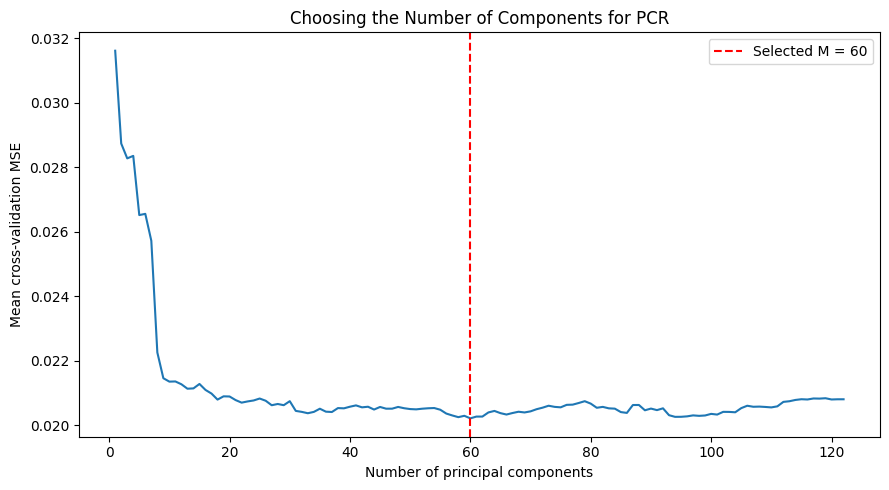

In [15]:
from sklearn.decomposition import PCA

pcr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("regression", LinearRegression())
])

pcr_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid={
        "pca__n_components": list(range(1, X_train_raw.shape[1] + 1))
    },
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=-1
)

pcr_search.fit(X_train_raw, y_train)
pcr_predictions = pcr_search.predict(X_test_raw)
pcr_mse = mean_squared_error(y_test, pcr_predictions)

model_results = [
    result for result in model_results
    if result["Model"] != "PCR"
]
model_results.append({
    "Model": "PCR",
    "Test MSE": pcr_mse,
    "Test RMSE": np.sqrt(pcr_mse),
    "Test R²": r2_score(y_test, pcr_predictions)
})

selected_M = pcr_search.best_params_["pca__n_components"]
explained_variance = (
    pcr_search.best_estimator_
    .named_steps["pca"]
    .explained_variance_ratio_
    .sum()
)

print("Selected number of components:", selected_M)
print(f"Best mean CV MSE: {-pcr_search.best_score_:.6f}")
print(f"Predictor variance retained: {explained_variance:.2%}")

display(pd.DataFrame(model_results).set_index("Model"))

plt.figure(figsize=(9, 5))
plt.plot(
    pcr_search.cv_results_["param_pca__n_components"].astype(int),
    -pcr_search.cv_results_["mean_test_score"]
)
plt.axvline(
    selected_M,
    color="red",
    linestyle="--",
    label=f"Selected M = {selected_M}"
)
plt.xlabel("Number of principal components")
plt.ylabel("Mean cross-validation MSE")
plt.title("Choosing the Number of Components for PCR")
plt.legend()
plt.tight_layout()
plt.show()

Cross-validation selected 60 principal components, retaining 98.06% of the standardized predictors’ variance. PCR achieved a test MSE of 0.018350 and a test R² of 0.6141. It performed worse than least squares, ridge, and both LASSO models on this test set. Retaining most predictor variance does not guarantee better prediction because PCA finds directions of high predictor variance without using the response.

### (j) L1-regularized gradient boosting

I fit an XGBoost tree ensemble and choose its L1 regularization parameter, reg_alpha, using five-fold cross-validation to minimize mean squared error. I keep the other model settings fixed and perform median imputation within each training fold.

In XGBoost’s tree booster, the L1 penalty applies to leaf weights; it does not fit a separate LASSO regression at each node. This implements the assignment’s suggested XGBoost approach.

In [16]:
from xgboost import XGBRegressor

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBRegressor(
        objective="reg:squarederror",
        booster="gbtree",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        subsample=1.0,
        colsample_bytree=1.0,
        reg_lambda=1.0,
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid={
        "xgb__reg_alpha": np.concatenate((
            [0.0],
            np.logspace(-4, 2, 25)
        ))
    },
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=-1
)

xgb_search.fit(X_train_raw, y_train)
xgb_predictions = xgb_search.predict(X_test_raw)
xgb_mse = mean_squared_error(y_test, xgb_predictions)

model_results = [
    result for result in model_results
    if result["Model"] != "XGBoost"
]
model_results.append({
    "Model": "XGBoost",
    "Test MSE": xgb_mse,
    "Test RMSE": np.sqrt(xgb_mse),
    "Test R²": r2_score(y_test, xgb_predictions)
})

print("Selected reg_alpha:",
      xgb_search.best_params_["xgb__reg_alpha"])
print(f"Best mean CV MSE: {-xgb_search.best_score_:.6f}")

display(pd.DataFrame(model_results).set_index("Model"))

Selected reg_alpha: 0.1
Best mean CV MSE: 0.019907


,Test MSE,Test RMSE,Test R²
Model,,,
Least squares,0.017966,0.134038,0.622204
Ridge,0.017349,0.131714,0.635192
LASSO without standardization,0.017627,0.132766,0.629341
LASSO with standardization,0.017736,0.133176,0.627047
PCR,0.018350,0.135460,0.614143
XGBoost,0.016422,0.128148,0.654678


Cross-validation selected an L1 regularization parameter of 0.1 for XGBoost, with a mean validation MSE of 0.019907. The fitted model achieved a test MSE of 0.016422, RMSE of 0.128148, and R² of 0.654678.

Among the models evaluated, XGBoost achieved the lowest test MSE, followed by ridge regression. XGBoost’s test MSE was approximately 8.6% lower than least squares. Although LASSO without standardization had the lowest cross-validation MSE among the tuned models, XGBoost performed best on the held-out test set. This illustrates that cross-validation and test-set rankings can differ.